<a href="https://colab.research.google.com/github/jose2049/ml-project-colab/blob/main/CampusDataSet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Campus data project
###José Álvarez



##Data preparation


In [8]:
import pandas as pd

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
df = pd.read_csv('/content/drive/MyDrive/Machine Learning/CampusWalkDataset_TemplateIDs_final.csv', skiprows=4)

#Inspect the dataset structure

## 1 Errasing empty rows and collums


In [11]:
from re import sub
from numpy._core.defchararray import index
#Eliminating extra columns
df = df.drop(columns=['other_notes', 'Unnamed: 23', 'Unnamed: 24','Unnamed: 25', 'Unnamed: 26'])
#list(df.columns)
# Droping all empty rows. The cahnges take place in the variable df
df.dropna(subset=['date'], inplace=True)
#list(df.index)
print(df.shape)

(135, 22)


#Fixing Teperature Colum
### decimal numbers
### mix between numbers and letters

In [12]:
import numpy as np

# 1. Strip non-numeric characters (except for strings like 'none' which we temporarily convert to NaN)
temp_raw = df["temperature_c"].astype(str).str.replace(r"[^0-9.]", "", regex=True)
temp_numeric = pd.to_numeric(temp_raw, errors='coerce')

# 2. Correct decimal scaling issues (e.g., converting 165 back to 16.5)
temp_numeric = temp_numeric.apply(lambda x: x / 10 if x > 60 else x)

# 3. Round up to the nearest integer
temp_rounded = np.ceil(temp_numeric)

# 4. Save back to the DataFrame and handle missing values as 'none'
df["temperature_c"] = temp_rounded.fillna('none')

# Display the unique sorted values and the DataFrame to verify
print("Unique cleaned temperatures:", sorted(df['temperature_c'].unique(), key=lambda x: (isinstance(x, str), x)))
display(df.head())


Unique cleaned temperatures: [np.float64(10.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0)]


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,...,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,...,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,...,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,...,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,...,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area


#Errasing Non numberic values (NaN)

In [13]:
list(df.columns)

['recorder_id',
 'date',
 'location',
 'weather',
 'temperature_c',
 'sound level',
 'foot_traffic',
 'primary_sound_type_urban',
 'other_sound_type_urban',
 'primary_sound_type_nature',
 'other_sound_type_nature',
 'insects_count',
 'birds_count',
 'trees_presence',
 'native_or_wild_plant_presence',
 'ornnamental_or_planted_plant_presence',
 'moss_or_lichen_presence',
 'wellbeing_rating',
 'ease_rating',
 'stress_rating',
 'nature_connection_experience_rating',
 'most_notable_nature_element']

In [14]:
## This for loop runs thorught the entire dataset
## and exchanges the NaN value to none

for index, row in df.iterrows():
    for column in df.columns:
        value = row[column]

        if pd.isna(value):
            df.loc[index, column] = "none"

df

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,...,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,...,2.0,Many,none,Some,none,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,...,20.0,Many,none,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,...,2.0,One or two,Some,none,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,...,0.0,One or two,none,Some,none,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,R26_027,23/09/2026,L04 PathFrontiHub,Windy,16.0,Quiet,Low,Traffic,Human voices,Trees,...,2.0,Many,Some,Some,none,Positive wellbeing,Easy,Mostly calm,Much more connected,Plants
134,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Quiet,Low,Other,Human voices,Wind,...,0.0,One or two,none,none,none,Neutral,Easy,Mostly calm,Less connected,Trees
135,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Moderate,Low,Traffic,Other,Wind,...,1.0,Many,Many,none,Some,Positive wellbeing,Easy,Very calm,Much more connected,plants
136,R26_028,07/10/2026,L01 MainEntrance,Partly cloudy,15.0,Moderate,Moderate,Traffic,Construction,Other birds,...,0.0,Many,Some,none,Many,Positive wellbeing,Neutral,Neutral,No change,grass


In [15]:
print(df.head(10).to_string(index=False))
print(df.shape)

recorder_id       date                       location       weather  temperature_c sound level foot_traffic primary_sound_type_urban other_sound_type_urban primary_sound_type_nature other_sound_type_nature  insects_count  birds_count trees_presence native_or_wild_plant_presence ornnamental_or_planted_plant_presence moss_or_lichen_presence        wellbeing_rating ease_rating stress_rating nature_connection_experience_rating most_notable_nature_element
    R26_001 22/09/2026               L01 MainEntrance Partly cloudy           16.0       Quiet          Low             Human voices                Traffic                      Wind                   Trees            0.0          1.0           Many                         Some                                  Some                     Some      Positive wellbeing     Neutral     Stressful                      Less connected            Plants and trees
    R26_001 22/09/2026               L02 LibraryGreen         Sunny           16.0    Mode

# Fixing values for weather

In [16]:
# Here I want to have all the values for weather in lowercase
df['weather'] = df['weather'].astype(str).str.lower()

# Let's verify the unique values now
print(df['weather'].unique())

['partly cloudy' 'sunny' 'windy' 'cloudy']


## I want to apply K-means clustering
## What do I need to apply this?

#1st I need to assign numerical values to each dataset
### How? and which dataset do I want to use?

# Here I am going to use K means clustering to group location with weather and temperature


In [17]:
# I need to know how many locations do I have
unique_locations = df['location'].unique()
print(f"Total unique locations: {len(unique_locations)}")
print("\nList of unique locations:")
for loc in sorted(unique_locations):
    print(f"- {loc}")

Total unique locations: 9

List of unique locations:
- L01 MainEntrance
- L02 LibraryGreen
- L03 LowerSidePathiHub
- L04 PathFrontiHub
- L05 GreenFrontSportsCentre
- L06 HedgingBehindSportsCentre
- L07 CarParkNearSportsCentre
- L08 AccessRoadNearSportsCentre
- L10 OtherOffCampus


In [18]:
# Now I'm going to add a value for each location
location = {
    'L01 MainEntrance': 1,
    'L02 LibraryGreen': 2,
    'L03 LowerSidePathiHub': 3,
    'L04 PathFrontiHub': 4,
    'L05 GreenFrontSportsCentre': 5,
    'L06 HedgingBehindSportsCentre': 6,
    'L07 CarParkNearSportsCentre': 7,
    'L08 AccessRoadNearSportsCentre': 8,
    'L10 OtherOffCampus': 10,
}
#Here I am creating a new column with location encoded
df['location_encoded'] = df['location'].map(location)

In [19]:
# Now I need to all the types of weather that I have available
unique_weather = df['weather'].unique()
print(f"Total unique weather: {len(unique_weather)}")
print("\nList of unique weather:")
for weather in sorted(unique_weather):
    print(f"- {weather}")

Total unique weather: 4

List of unique weather:
- cloudy
- partly cloudy
- sunny
- windy


In [20]:
# Here I am assigning a value to each weather type using lowercase keys
weather_mapping = {
    'cloudy': 1,
    'partly cloudy': 2,
    'sunny': 3,
    'windy': 4
}

# Let's map these values to a new column
df['weather_encoded'] = df['weather'].map(weather_mapping)

In [21]:
# Now I need to know what king of temperature values do I have
unique_temperature = df['temperature_c'].unique()
print(f"Total unique temperature: {len(unique_temperature)}")
print("\nList of unique temperature:")
for temperature in sorted(unique_temperature):
    print(f"- {temperature}")

Total unique temperature: 8

List of unique temperature:
- 10.0
- 13.0
- 14.0
- 15.0
- 16.0
- 17.0
- 18.0
- 19.0


## It turns out that I don't need to encode temperature because the data is already in a numeric format

In [22]:
# Here I am assigning values to each weather type
temperature_mapping = {
    'none': 0,
    '10.0': 1,
    '13.0': 2,
    '14.0': 3,
    '15.0': 4,
    '16.0': 5,
    '17.0': 6,
    '18.0': 7,
    '19.0': 8
}

# What do I need to use K-means?
## https://www.tutorialspoint.com/machine_learning/machine_learning_k_means_clustering.htm

### Preparing the Features
We will ensure `temperature_c` is fully numeric, combine our three features (`location_encoded`, `weather_encoded`, `temperature_c`), handle any remaining missing values, and scale them using `StandardScaler`.

In [23]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure temperature is numeric (convert 'none' to NaN first, then we can fill it with the median temperature)
df['temperature_numeric'] = pd.to_numeric(df['temperature_c'], errors='coerce')
median_temp = df['temperature_numeric'].median()
df['temperature_numeric'] = df['temperature_numeric'].fillna(median_temp)

# 2. Select our three features for clustering
features = ['location_encoded', 'weather_encoded', 'temperature_numeric']
X = df[features].copy()

# Check for any unexpected NaN values in our features and fill them
X = X.fillna(0)

# 3. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features scaled successfully. Ready for clustering!")
display(pd.DataFrame(X_scaled, columns=features).head())

Features scaled successfully. Ready for clustering!


,location_encoded,weather_encoded,temperature_numeric
0,-1.475795,-1.031431,-0.486225
1,-1.045488,0.498714,-0.486225
2,0.675742,-1.031431,-0.486225
3,1.536357,-1.031431,-0.486225
4,0.675742,0.498714,-0.486225


### Determining the optimal number of clusters (Elbow Method) and Running K-Means
Let's find the optimal number of clusters and then run K-Means to assign each data point to a cluster.

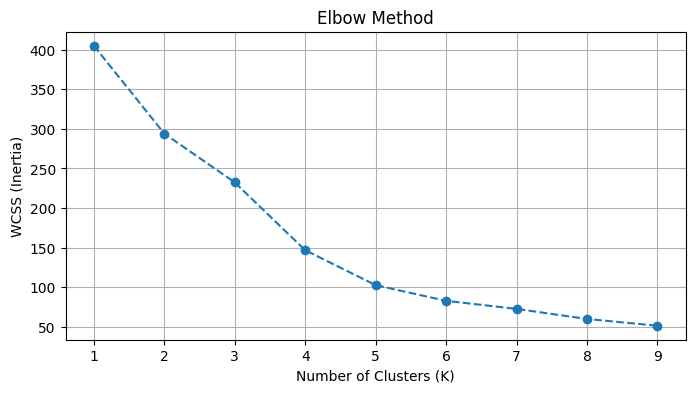

In [24]:
# Let's find the best number of clusters (K) using the Elbow Method
wcss = []
for i in range(1, 10):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), wcss, marker='o', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

Now, let's train K-Means with an selected cluster count (e.g., $k=3$) and analyze the groups.

In [25]:
# We will choose 3 clusters based on the elbow or features
k_optimal = 3
kmeans_model = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42, n_init='auto')
df['cluster'] = kmeans_model.fit_predict(X_scaled)

# Display the average profile of each cluster in original values
cluster_summary = df.groupby('cluster')[['location', 'weather', 'temperature_numeric']].agg(
    location_mode=pd.NamedAgg(column='location', aggfunc=lambda x: x.mode()[0] if not x.mode().empty else 'none'),
    weather_mode=pd.NamedAgg(column='weather', aggfunc=lambda x: x.mode()[0] if not x.mode().empty else 'none'),
    avg_temperature=pd.NamedAgg(column='temperature_numeric', aggfunc='mean'),
    count=pd.NamedAgg(column='temperature_numeric', aggfunc='count')
).reset_index()

display(cluster_summary)

,cluster,location_mode,weather_mode,avg_temperature,count
0,0,L01 MainEntrance,partly cloudy,16.447368,38
1,1,L04 PathFrontiHub,sunny,17.183333,60
2,2,L06 HedgingBehindSportsCentre,sunny,16.000000,37


### Visualizing the Clusters
Let's create a scatter plot with `location` on the x-axis, `temperature_numeric` on the y-axis, and color-code the points by their assigned `cluster` to see how they separate.

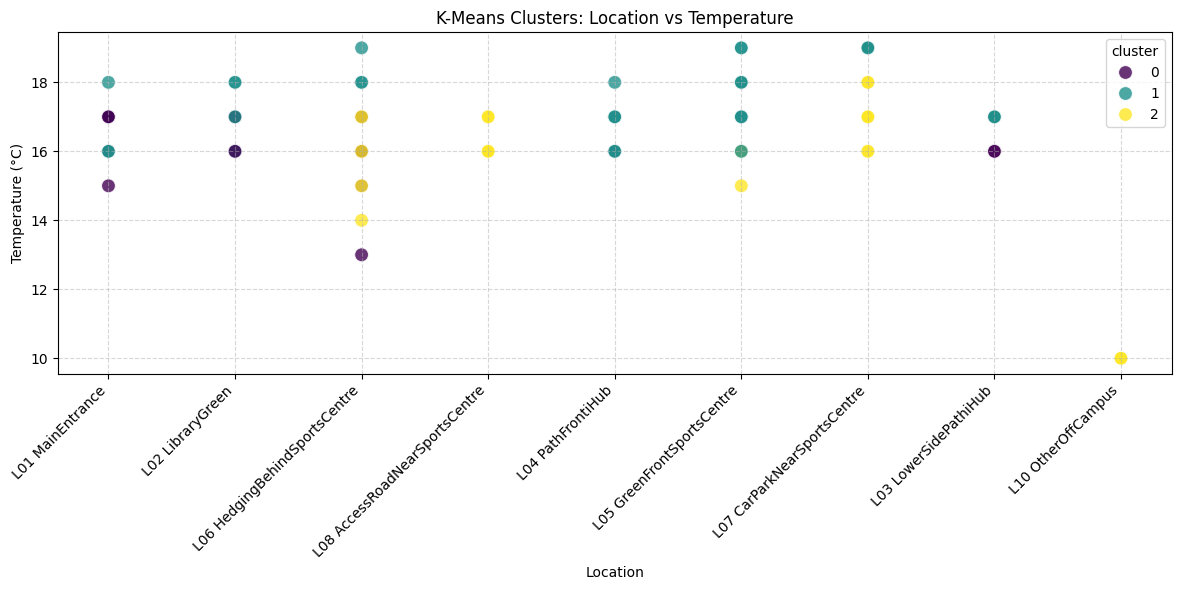

In [26]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x='location',
    y='temperature_numeric',
    hue='cluster',
    palette='viridis',
    s=100,
    alpha=0.8
)
plt.title('K-Means Clusters: Location vs Temperature')
plt.xlabel('Location')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interactive 3D Visualization of the 3 Features
We can use `plotly.express` to construct a 3D scatter plot.
* **X-axis:** Location (encoded)
* **Y-axis:** Weather (encoded)
* **Z-axis:** Temperature
* **Color:** Assigned Cluster

In [28]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='location_encoded',
    y='weather_encoded',
    z='temperature_numeric',
    color='cluster',
    hover_data=['location', 'weather', 'temperature_c'],
    title='3D Visualisation of Locations, Weather, and Temperature',
    labels={
        'location_encoded': 'Location (ID)',
        'weather_encoded': 'Weather (ID)',
        'temperature_numeric': 'Temperature (°C)'
    }
)

fig.show()